# Import the libraries


1.   numpy
2.   pandas
3.   pyplot from matplotlib
4.   seaborn





In [3]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print(f"NumPy version: {np.__version__}")
print(f"Pandas version: {pd.__version__}")

# complete

# Set random seed for complete reproducibility across runs
np.random.seed(1)

NumPy version: 2.4.6
Pandas version: 2.2.3


In [ ]:
# Evaluation cell, Skip it ...

# Exercise 1 (03 points)

The spam table of §4.2 is S = np.array([[10, 4], [2, 1], [7, 3], [1, 2]]) (links, words in
subject), weights Θ = (0.3, 0.7), bias 0.5.
1. Compute z = S @ np.array([0.3, 0.7]) + 0.5 and check that the first value is 6.3 as in the lecture.
2. Apply the sigmoid 1 / (1 + np.exp(-z)) to the whole vector. Which e-mails are predicted as spam
(probability ≥ 0.5)?

In [4]:
# Write your code here

S = np.array([[10, 4], [2, 1], [7, 3], [1, 2]])
theta = np.array([0.3, 0.7])
bias = 0.5

# 1. Compute linear combination z
z = S @ theta + bias
print(z)

# 2. Compute sigmoid probabilities and predict spam (probability >= 0.5)
probabilities =1 / (1 + np.exp(-z))
print(probabilities)
# Identify predicted spam emails
predicted_spam = probabilities>=0.5
print(predicted_spam)

[6.3 1.8 4.7 2.2]
[0.99816706 0.85814894 0.9909867  0.90024951]
[ True  True  True  True]


In [ ]:
# Auto-graded cell (S)
# Skip it

In [ ]:
# Auto-graded cell (theta)
# Skip it

In [ ]:
# Auto-graded cell (bias)
# Skip it

In [ ]:
# Auto-graded cell (z)
# Skip it

In [ ]:
# Auto-graded cell (probabilities)
# Skip it

In [ ]:
# Auto-graded cell predicted_spam
# Skip it

# Exercise 2 (05 points)
Let's create a log of 300 login events with a few missing values and a few suspicious bursts of failed attempts.

In [5]:
# Create the log of 300 login events with a few missing values and a few suspicious bursts of failed attempts.
rng = np.random.default_rng(1)
n = 300
log = pd.DataFrame({"user":    rng.choice(["ali", "sara", "yacine", "nour", "karim"], n),
                    "hour":    rng.integers(0, 24, n),
                    "failed_attempts": rng.poisson(0.4, n),
                    "country": rng.choice(["DZ", "FR", "TN", "RU"], n, p=[.7, .15, .1, .05]),
                    "duration_min": rng.gamma(2, 8, n).round(1)})

In [ ]:
# Auto graded cell (log)
# skip it

In [16]:
# Choose randomly 12 different indexes and set 12 integer values from [5,11[ in the feature "failed_attempt"
log.loc[
rng.choice(n, 12, replace=False),
"failed_attempts"
] = rng.integers(5, 11, 12)
# Write your code here

In [ ]:
# Autograded cell (Failed attempts)
# Skip it

In [17]:
# Insert 10 missing values randomly
log.loc[
rng.choice(n, 10, replace=False),
"duration_min"
] = np.nan
# Write your code here

In [ ]:
# Auto graded cell (missing values)
# skip it

1. How many logins come from Russia (RU) with at least 5 failed attempts?

In [18]:
# Write your code here

ru_log_at_least_five_attempts = log[
(log["country"] == "RU") &
(log["failed_attempts"] >= 5)
]

print("1. Number of suspicious logins from RU:")
print(len(ru_log_at_least_five_attempts))


1. Number of suspicious logins from RU:
2


In [ ]:
# Auto-graded cell (ru_log_at_least_five_attempts)
# Skip it

2. Which user has the highest total number of failed attempts? (groupby + sum + sort_values)

In [19]:
# Write your code here
user_max_failed_attempts = log.groupby("user")["failed_attempts"].sum()
user_max_failed_attempts = user_max_failed_attempts.sort_values(ascending=False)

print("\n2. Total failed attempts per user:")
print(user_max_failed_attempts)

print("User with the highest total:")
print(user_max_failed_attempts.idxmax())
# user_max_failed_attempts =


2. Total failed attempts per user:
user
yacine    58
ali       51
sara      42
karim     29
nour      27
Name: failed_attempts, dtype: int64
User with the highest total:
yacine


In [ ]:
# Auto-graded cell user_max_failed_attemps)
# Skip it

3. Add a column long_session equal to 1 when duration_min is above 30.

In [20]:
# Write your code here
# Add long_session column
log["long_session"] = (
log["duration_min"] > 30
).astype(int)

print("\n3. Long session column:")
print(log[["user", "duration_min", "long_session"]].head())

median = log["duration_min"].median()
log["duration_min"] = log["duration_min"].fillna(median)
log["night"] = (log["hour"] < 6).astype(int)



print("\nCleaned file saved: logins_clean.csv")
# log['long_session'] = ...


3. Long session column:
     user  duration_min  long_session
0  yacine          24.0             0
1  yacine          23.2             0
2    nour           4.8             0
3   karim           4.2             0
4     ali          21.8             0

Cleaned file saved: logins_clean.csv


In [ ]:
# Autograded cell - Skip it

# Exercise 3 (03 points)
1. Draw the histogram of failed_attempts.
2. Why is a histogram better than the mean (0.7) to describe this column?
3. Then draw a bar chart of the mean failed_attempts per night value.

     user  hour  failed_attempts country  duration_min  night  long_session
0  yacine     2                0      DZ          24.0      1             0
1  yacine    23                0      FR          23.2      0             0
2    nour    11                0      FR           4.8      0             0
3   karim     9                0      DZ           4.2      0             0
4     ali    17                0      DZ          21.8      0             0


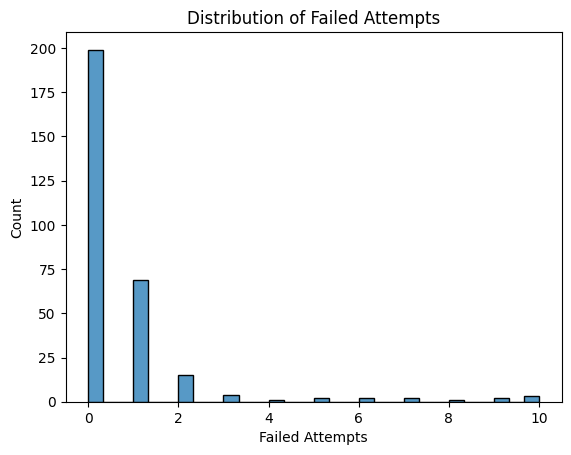

In [21]:
# Draw the histogram of failed_attempts.
print(log.head())
sns.histplot(log["failed_attempts"], bins=30)
plt.title("Distribution of Failed Attempts")
plt.xlabel("Failed Attempts")
plt.ylabel("Count")
plt.show()
# Write your code here

In [ ]:
# Auto-graded cell - Skip it...

In [ ]:
2. Why is a histogram better than the mean (0.7) to describe this column?
    A: The mean is too difficult to calculate.
    B: The distribution is highly skewed with zero-inflation and rare extreme bursts.
    C: Histograms only work with categorical data.
    D: The mean cannot be calculated for numeric values.

In [ ]:
# Write your code here
 answer_q2 = "B"

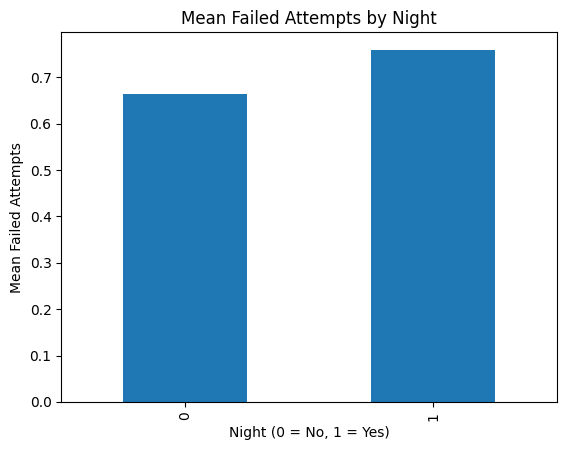

In [22]:
# 3. Draw a bar chart of the mean failed_attempts per night value.
# 3. Draw a bar chart of the mean failed_attempts per night value.
median = log["duration_min"].median()
log["duration_min"] = log["duration_min"].fillna(median)
log["night"] = (log["hour"] < 6).astype(int)


log.groupby("night")["failed_attempts"].mean().plot.bar()
plt.title("Mean Failed Attempts by Night")
plt.xlabel("Night (0 = No, 1 = Yes)")
plt.ylabel("Mean Failed Attempts")
plt.show()
# Write your code here

In [ ]:
# Auttograded cell - Skip it

Q1. If (300, 4) is the shape of a numpy array X.
What does X[:, 2] return? (01 point)

In [ ]:
# Write your code here
X[:, 2] returns all rows of the third column 3 of the array X
# Please write a sentence response instead of code

Q2. Give the Pandas command that shows the number of missing values in each column of a given df. (01 point)

In [7]:
# Write your code here
log.isna().sum()

,0
user,0
hour,0
failed_attempts,0
country,0
duration_min,0


Q3. Which plot would you use to see whether logins from RU have more failed attempts than logins from DZ? (01 point)

In [ ]:
# Write your code here
A box plot comparing failed attempts for RU and DZ logins

Q4. Why do we scale features before training a model (one sentence)? (01 point)

In [ ]:
# Write your code here
We scale features before training a model to ensure that all features have a similar scale and prevent features with larger values from dominating the model

Commit the logins_clean.csv.(0.5 point)

In [23]:
# save the cleaned table in login_clean.csv
log.to_csv("logins_clean.csv", index=False)
# Write your code here

In [ ]:
# Autograded cell - Skip it

# Bonus (02 points)
On logins_clean.csv, build the matrix X with the columns hour, failed_attempts,
duration_min, night using df[cols].to_numpy(), scale it as in Cell 1.5, and print its shape. This is exactly the input Workshop 2 will feed to Scikit-learn.

In [15]:
# Write your code here
import pandas as pd
import numpy as np
df = pd.read_csv("logins_clean.csv")
cols = ["hour", "failed_attempts", "duration_min", "night"]
X = df[cols].to_numpy()
X_scaled = (X - X.mean(axis=0)) / X.std(axis=0)
print("X shape:", X.shape)
print("X_scaled shape:", X_scaled.shape)

X shape: (300, 4)
X_scaled shape: (300, 4)


In [8]:
import numpy as np
import pandas as pd
